In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv("uber.csv")

In [3]:
print("Original Dataset:")
df.head()

Original Dataset:


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [5]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [6]:
df.dropna(inplace=True)

In [7]:
df.drop(columns=["Unnamed: 0", "key"], errors="ignore", inplace=True)

In [8]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

In [9]:
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year

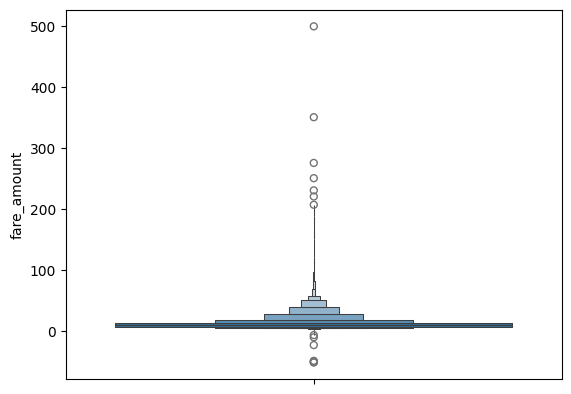

In [10]:
sns.boxenplot(df["fare_amount"])
plt.show()

In [11]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df['fare_amount'] >= lower) & (df['fare_amount'] <= upper) ]

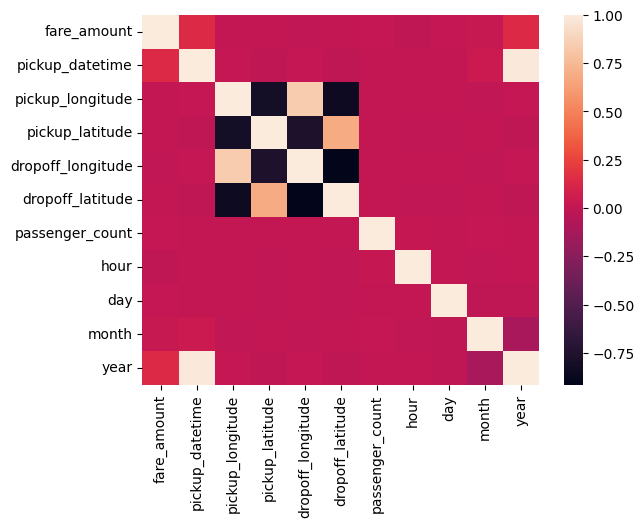

In [12]:
sns.heatmap(df.corr(),annot=False)
plt.show()

In [13]:
x = df.drop(['fare_amount', 'pickup_datetime'], axis=1)
y = df['fare_amount']

In [14]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)

print(x_train.shape, x_test.shape, y_train.shape ,y_test.shape)

(146266, 9) (36567, 9) (146266,) (36567,)


In [15]:
lr = LinearRegression()
lr.fit(x_train, y_train)
y_pred_lr = lr.predict(x_test)

rf = RandomForestRegressor(
    n_estimators=50, random_state=42, n_jobs=-1
)
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)

In [16]:
print("Linear Regression:-")
print("R2 Score",round(r2_score(y_test,y_pred_lr),4))
print("RMSE",round(mean_squared_error(y_test,y_pred_lr),4))
print("MAE",round(mean_absolute_error(y_test,y_pred_lr),4))

print("Random Forest Regression:-")
print("R2 Score",round(r2_score(y_test,y_pred_rf),4))
print("RMSE",round(mean_squared_error(y_test,y_pred_rf),4))
print("MAE Score",round(mean_absolute_error(y_test,y_pred_rf),4))

Linear Regression:-
R2 Score 0.0214
RMSE 16.7468
MAE 3.2413
Random Forest Regression:-
R2 Score 0.7512
RMSE 4.2586
MAE Score 1.4104


In [17]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_rf)
    ]
})

print("\nModel Comparison:")
print(results)


Model Comparison:
               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.021405  4.092282  3.241290
1      Random Forest  0.751152  2.063626  1.410381
